In [1]:
import numpy as np
from matplotlib import pyplot as plt
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
from scipy.sparse.linalg import svds

In [446]:
import seaborn as sns

In [11]:
n_timepoints = 5000
series = np.zeros(n_timepoints)

x = 0
a = 0.9

b = 0

firing_prop = 0.003
spikes = (np.random.rand(n_timepoints) < firing_prop).astype(float)

for i in range(2, n_timepoints):
    series[i] = (a * series[i - 1]) + (b * series[i - 2]) + (50 * spikes[i])

# Choose coefficient `a` randomly for each spike

In [395]:
kernel = np.zeros(20)

kernel[0] = 50
for i in range(1, kernel.size):
    kernel[i] = (a * kernel[i - 1])

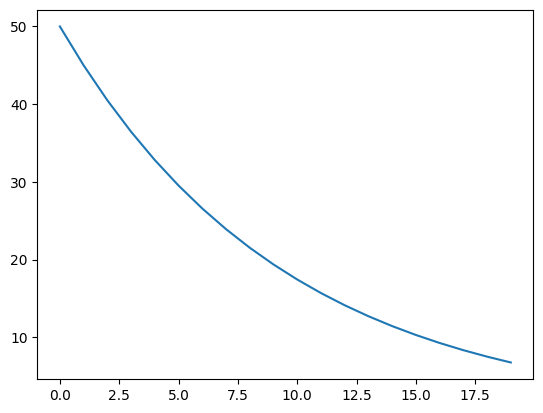

In [396]:
plt.plot(kernel)

<Axes: >

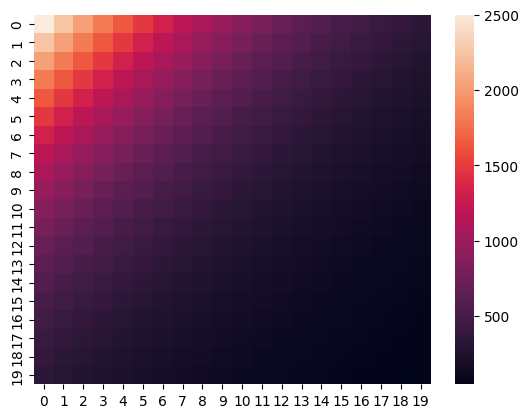

In [453]:
kkt = np.outer(kernel, kernel.T)

sns.heatmap(kkt)

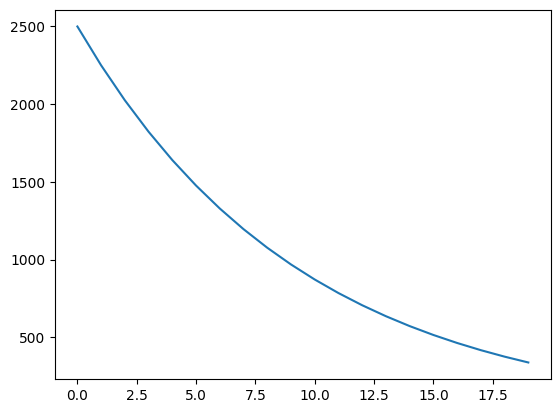

In [454]:
plt.plot(kkt[0])

In [455]:
from scipy import linalg

<Axes: >

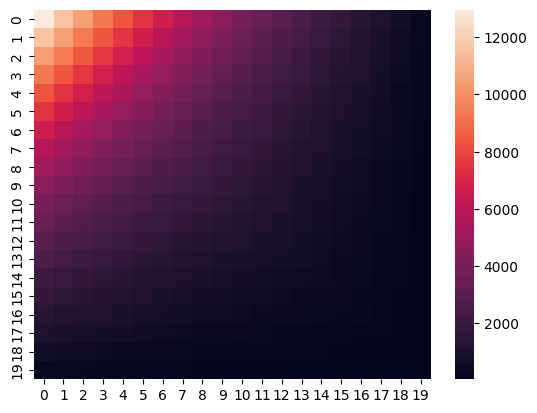

In [457]:
H = linalg.hankel(kernel)

sns.heatmap(H @ H.T)

<StemContainer object of 3 artists>

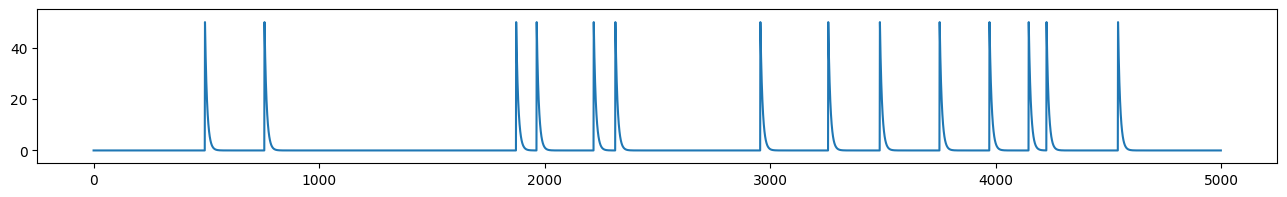

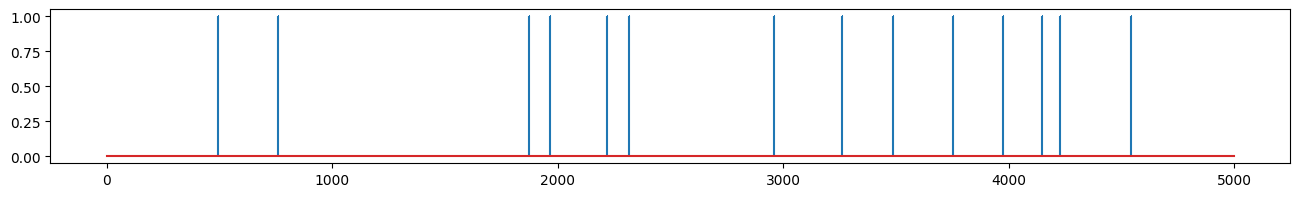

In [397]:
fig = plt.figure(figsize=(16, 2))
plt.plot(series)
plt.ylim(series.min() - 5, series.max() + 5)

fig = plt.figure(figsize=(16, 2))
plt.stem(spikes, markerfmt=",")

(-56.84889695878053, 80.88352543590534)

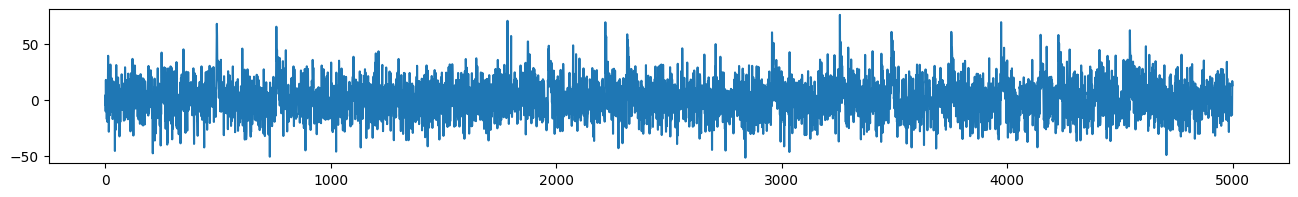

In [422]:
series_noise = series + np.random.normal(scale=15, size=series.size)

fig = plt.figure(figsize=(16, 2))
plt.plot(series_noise)
plt.ylim(series_noise.min() - 5, series_noise.max() + 5)

In [423]:
trace = series_noise
trace = trace[::-1]

In [424]:
window_size = 10

In [425]:
n_rows = window_size
hankel = np.zeros((n_rows, series.size - n_rows), dtype=np.float32)
for i in range(n_rows):
    start = i
    stop = -n_rows + i
    hankel[i] = trace[start:stop]

In [426]:
u, s, v = svds(hankel, k=4)
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

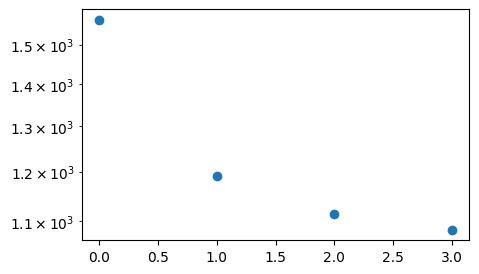

In [427]:
fig = plt.figure(figsize=(5, 3))
plt.scatter(np.arange(s.size), s)
plt.yscale("log")

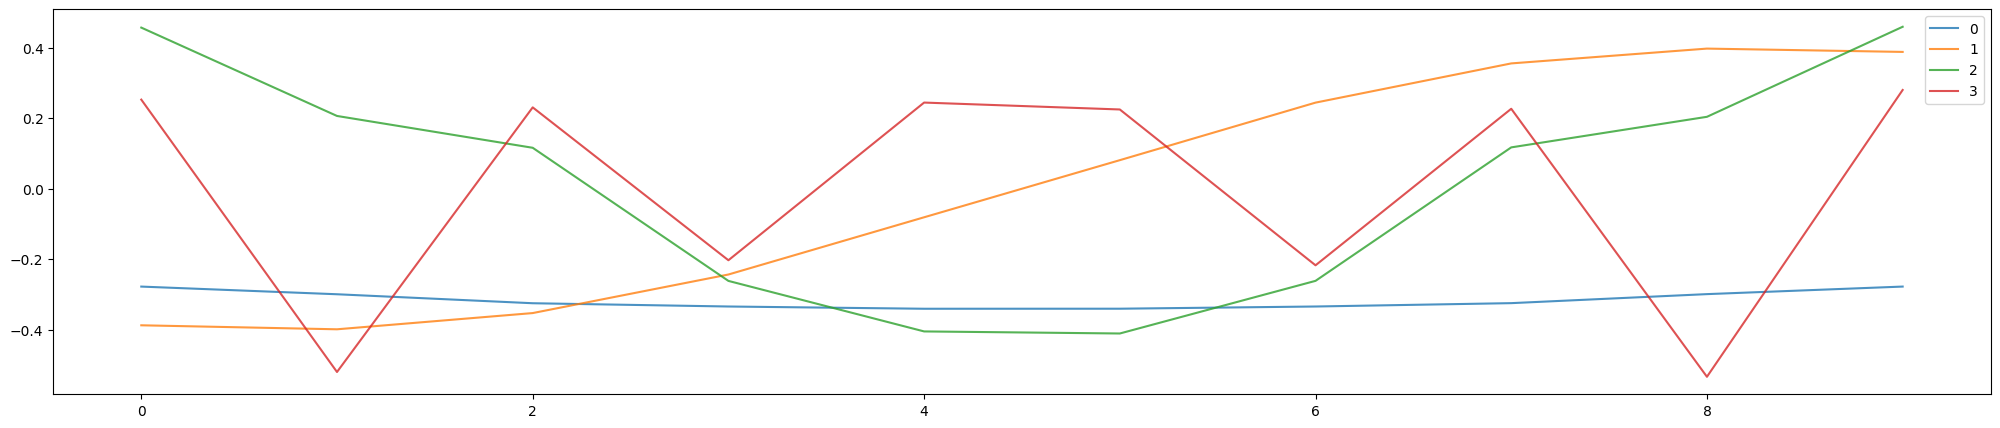

In [428]:
fig = plt.figure(figsize=(25, 5))
for i in range(s.size):
    plt.plot(u[:, i], alpha=0.8, label=str(i))
    # break
plt.legend()

In [429]:
s_t = s.copy()
s_t[3:] = 0

r = u @ np.diag(s_t) @ v

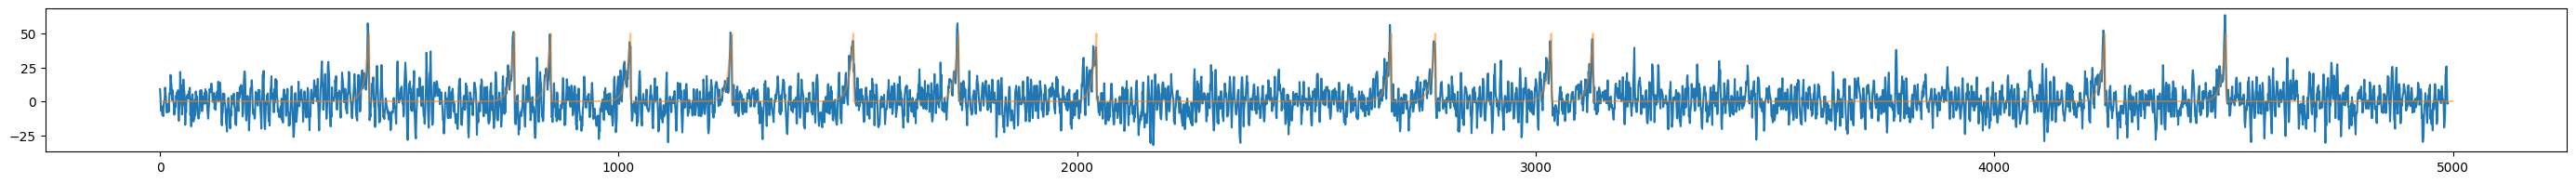

In [430]:
fig = plt.figure(figsize=(35, 2))
plt.plot(r[0])
plt.plot(series[::-1], alpha=0.5)

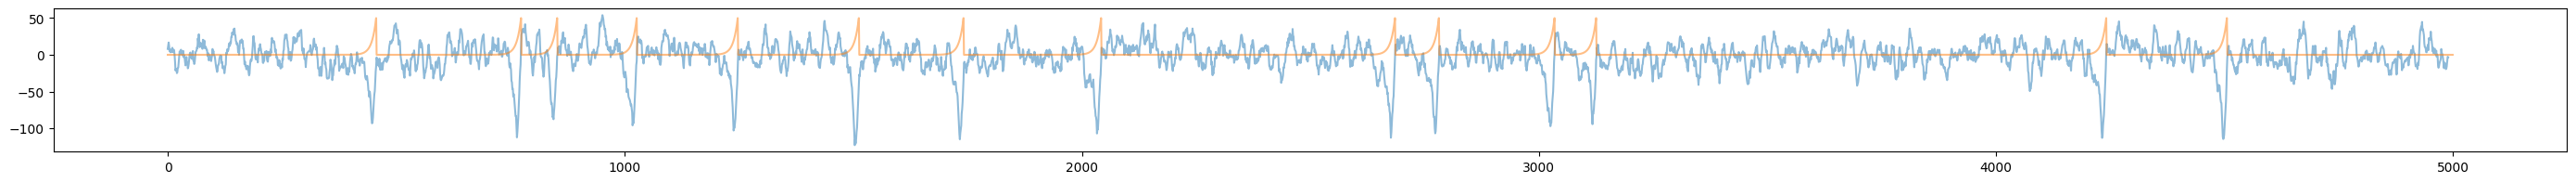

In [431]:
fig = plt.figure(figsize=(35, 2))
plt.plot(v[0] * s[0], alpha=0.5)
plt.plot(series[::-1], alpha=0.5)

In [432]:
filter_size = window_size * 2
filt = np.concatenate([np.arange(0, filter_size / 2), np.arange(filter_size / 2, 0, -1)])
filtered = np.zeros(series.size)

for i in range(filtered.size - filt.size):
    filtered[i] = np.dot(series_noise[i:i + filt.size], filt) / np.linalg.norm(filt)

In [433]:
ideal_filtered = np.zeros(series.size)

for i in range(ideal_filtered.size - kernel.size):
    ideal_filtered[i] = np.dot(series_noise[i:i + kernel.size], kernel) / np.linalg.norm(kernel)

In [434]:
def get_window_hankel(s: np.ndarray, timepoint: int, n_steps: int):
    h = np.zeros((n_steps, n_steps), dtype=np.float32)
    for i in range(n_steps):
        start = timepoint + i
        stop = start + n_steps
        h[i] = s[start:stop]

    return h

In [435]:
singular_vals = np.zeros(n_timepoints)
sgap = np.zeros(n_timepoints)
n_steps = window_size

for i in range(n_steps, n_timepoints - (n_steps * 2)):
    h = get_window_hankel(trace, timepoint=i - n_steps, n_steps=n_steps)
    _u, _s, _v = svd(h)
    singular_vals[i] = _s[0]
    sgap[i] = _s[0] - _s[1]
    

singular_vals = singular_vals[::-1]
sgap = sgap[::-1]

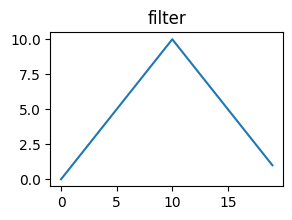

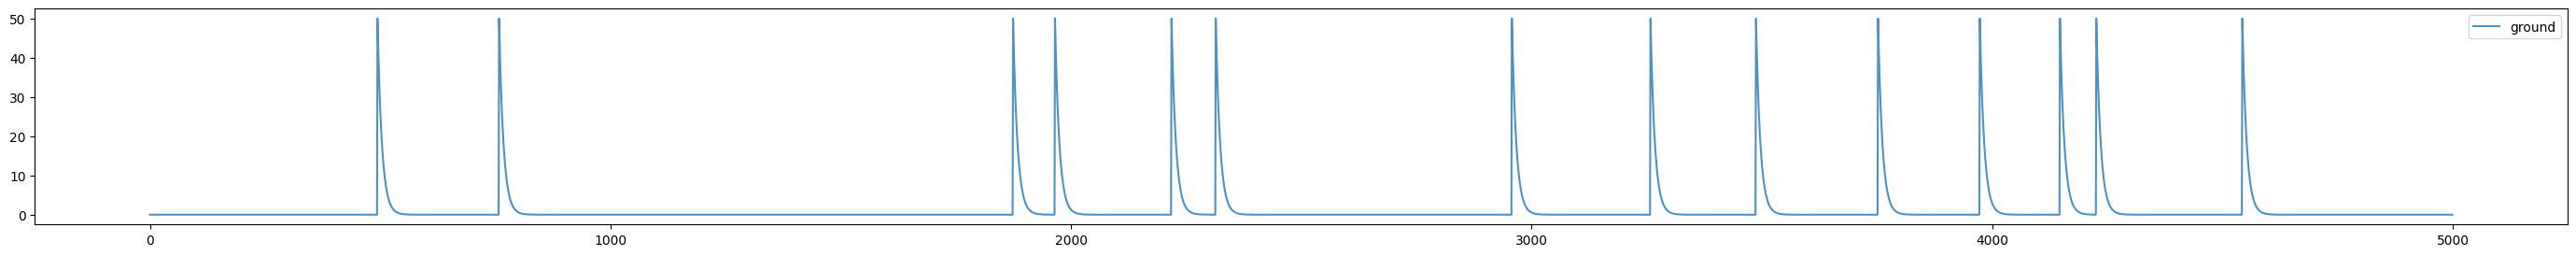

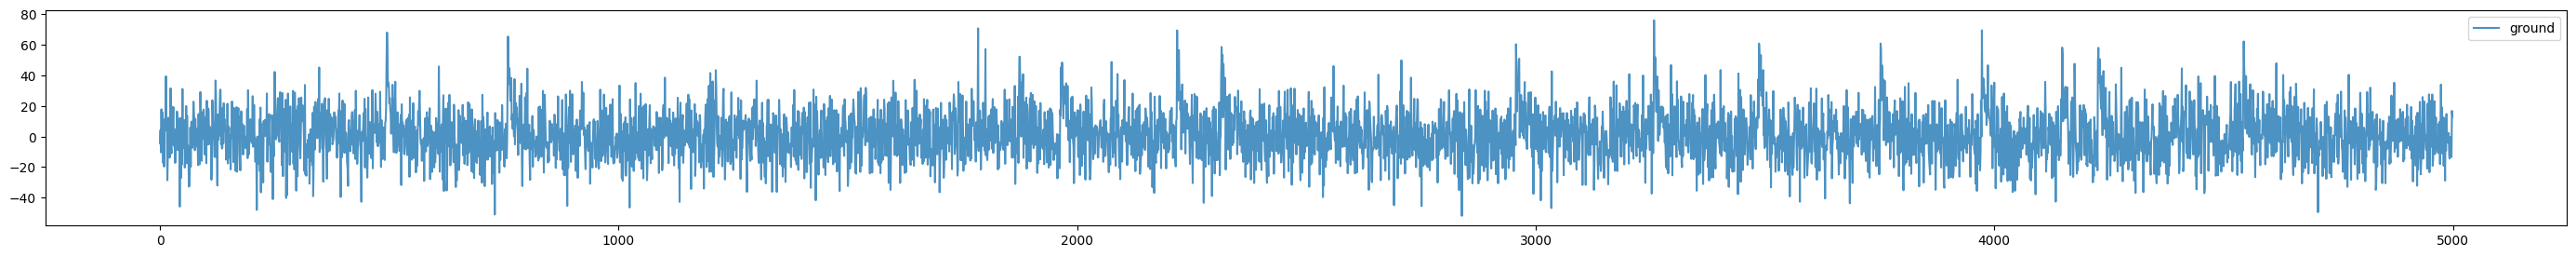

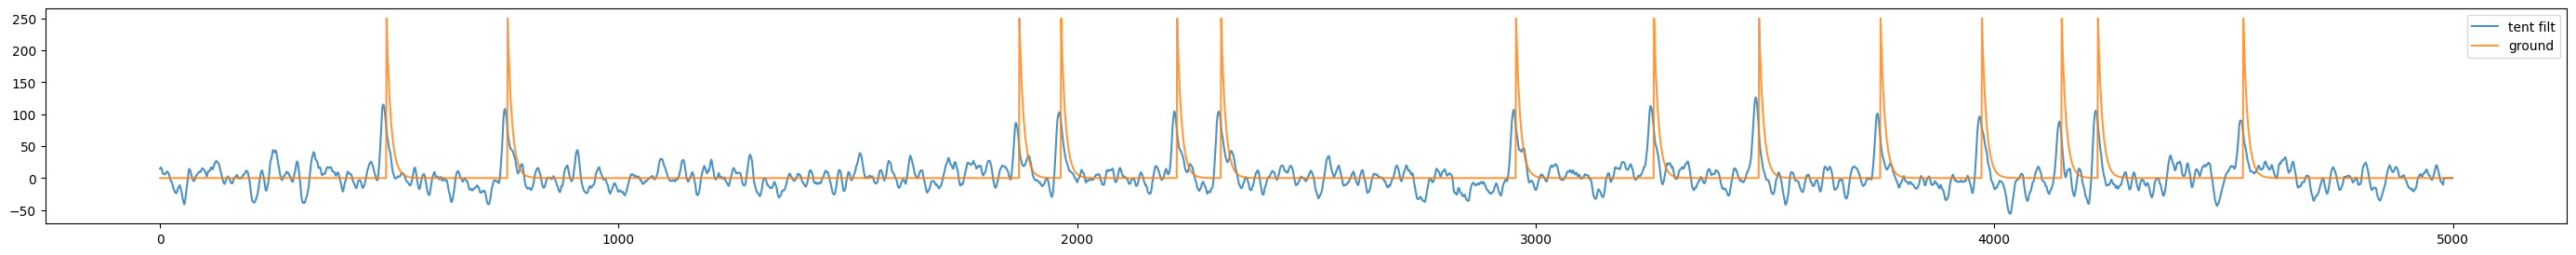

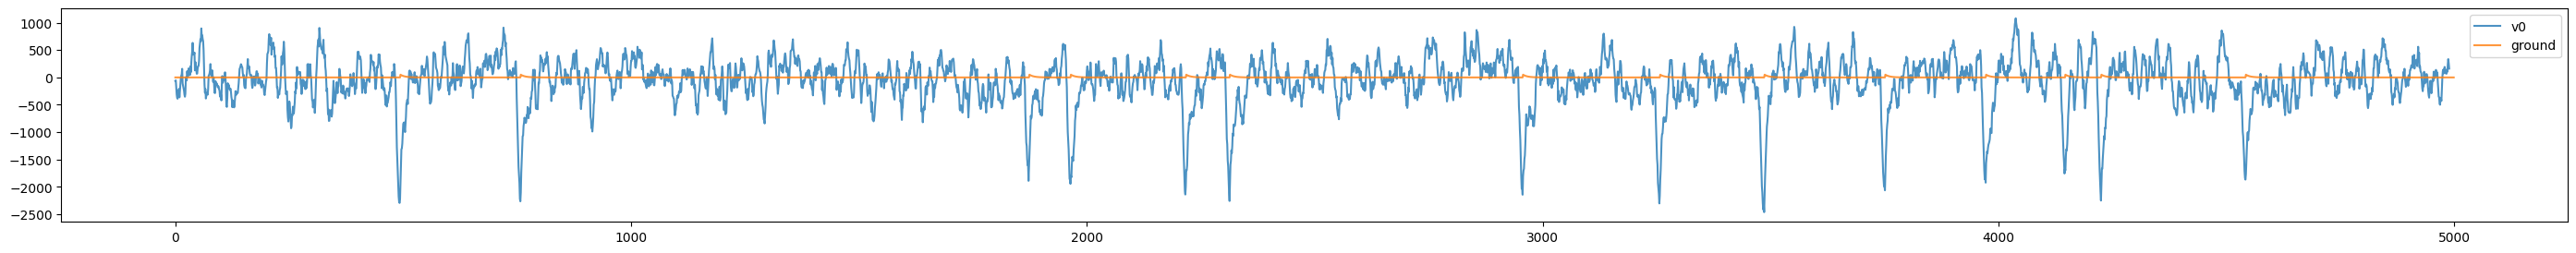

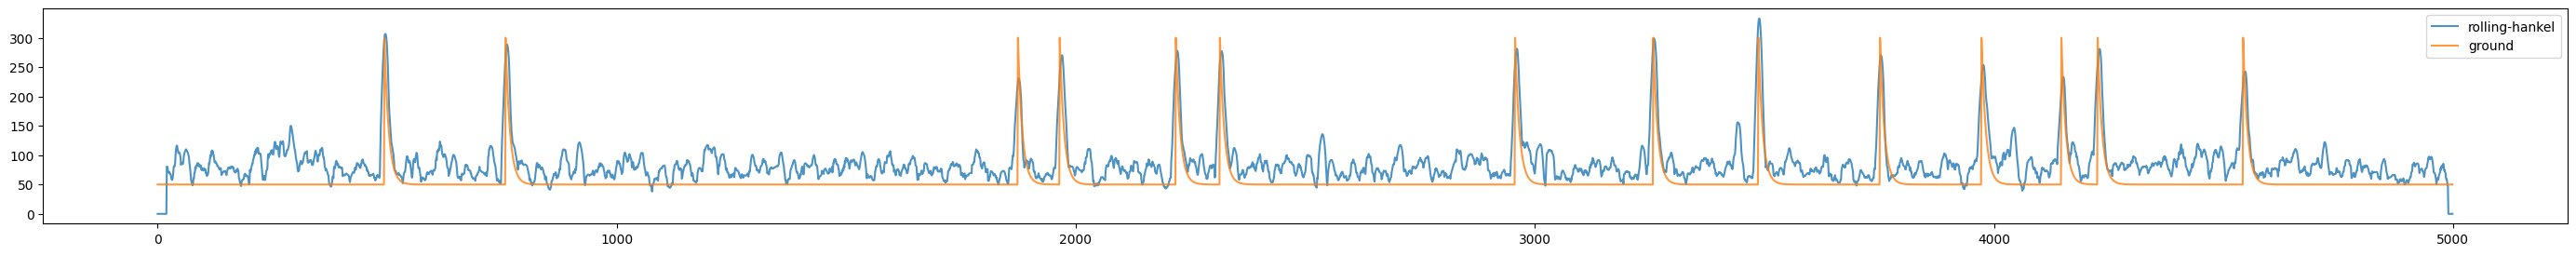

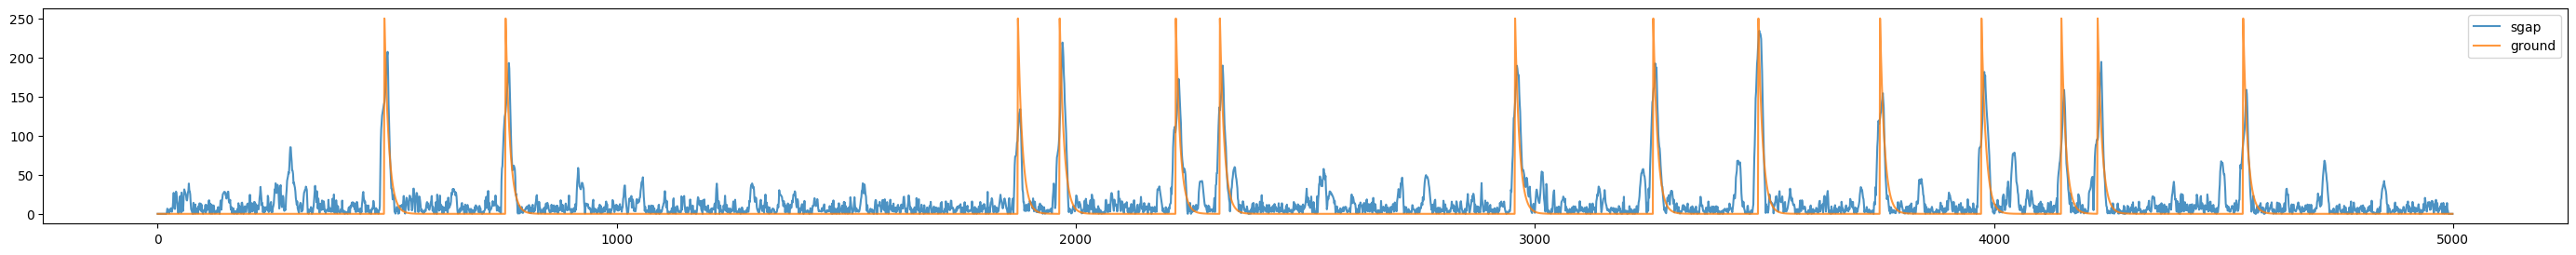

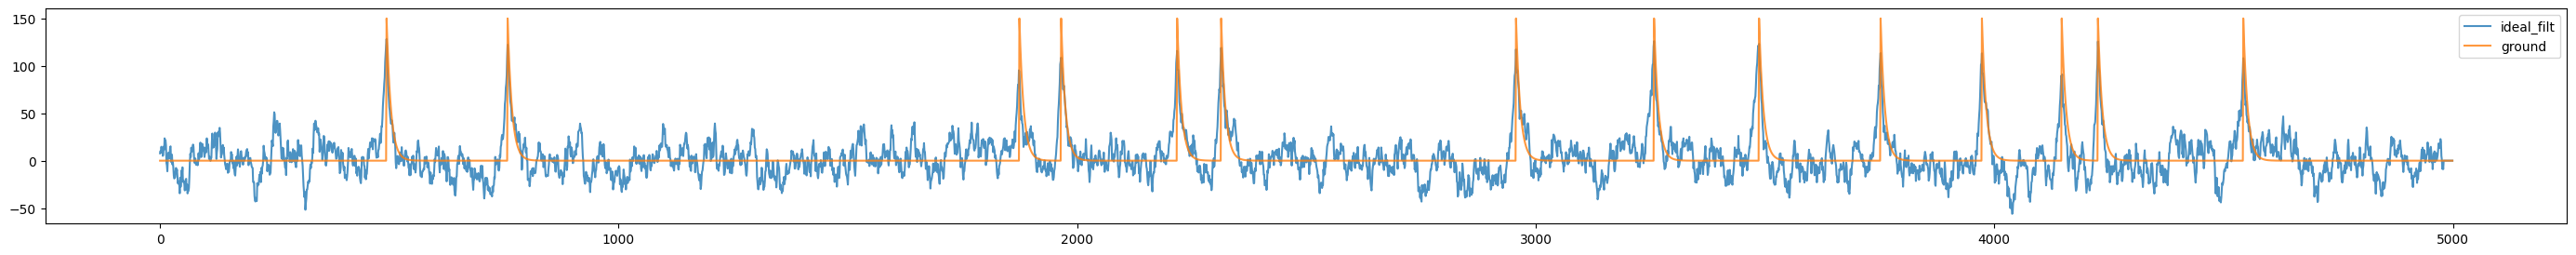

In [437]:
fig = plt.figure(figsize=(3, 2))
plt.plot(filt)
plt.title("filter")

fig = plt.figure(figsize=(35, 3))
plt.plot(series, alpha=0.8, label="ground")
plt.legend()

fig = plt.figure(figsize=(35, 3))
plt.plot(series_noise, alpha=0.8, label="ground")
plt.legend()

fig = plt.figure(figsize=(35, 3))
plt.plot(filtered, alpha=0.8, label="tent filt")
plt.plot((series * 5) + 0, alpha=0.8, label="ground")
plt.legend()

fig = plt.figure(figsize=(35, 3))
plt.plot(v[0][::-1] * s[0] * 20, alpha=0.8, label="v0")
plt.plot(series, alpha=0.8, label="ground")
plt.legend()

fig = plt.figure(figsize=(35, 3))
plt.plot(singular_vals, alpha=0.8, label="rolling-hankel")
plt.plot((series * 5) + 50, alpha=0.8, label="ground")
plt.legend()

fig = plt.figure(figsize=(35, 3))
plt.plot(sgap, alpha=0.8, label="sgap")
plt.plot((series * 5) + 0, alpha=0.8, label="ground")
plt.legend()

fig = plt.figure(figsize=(35, 3))
plt.plot(ideal_filtered, alpha=0.8, label="ideal_filt")
plt.plot((series * 3) + 0, alpha=0.8, label="ground")
plt.legend()


In [351]:
from scipy.linalg import svd

In [352]:
gp = fpl.Figure((5, 1), names=[["series"], ["hankel"], ["singular-values"], ["u"], ["v"]])

series_line = gp["series"].add_line(trace, name="noisy", colors="blue", alpha=0.5)
series_clean = gp["series"].add_line(series[::-1], colors="w", thickness=4, alpha=0.5, name="ground")
sgap_g = gp["series"].add_line(sgap[::-1], colors="y", alpha=.5, name="sgap")

sel = series_line.add_linear_selector()

legend = fpl.Legend(gp["hankel"].docks["right"])

singular_values_line = gp["series"].add_line(singular_vals[::-1] / 6, colors="magenta", name="svals-rolling")

filt_line = gp["series"].add_line(filtered[::-1], colors="cyan", alpha=0.5, name="filtered")

for g in [series_line, series_clean, singular_values_line, filt_line]:
    legend.add_graphic(g, label=g.name)
gp["hankel"].docks["right"].size = 300

hankel = get_window_hankel(trace, timepoint=10, n_steps=10)
img = gp["hankel"].add_image(hankel, name="hankel")
img.cmap.vmax = series.max()

def update_hankel(ev):
    ix = ev.pick_info["selected_index"]
    if ix < 11:
        return
    hankel = get_window_hankel(trace, timepoint=ix - 10, n_steps=10)
    img.data = hankel

    U, S, V = svd(hankel)
    U = U#[:, ::-1]
    S = S#[::-1]
    V = V#[::-1]
    
    gp["singular-values"].clear()
    gp["singular-values"].add_scatter(np.column_stack([np.arange(S.size), S]), sizes=10)
    gp["singular-values"].auto_scale()

    gp["u"].clear()
    gp["u"].add_image(U)

    gp["v"].clear()
    gp["v"].add_image(V)
    

sel.selection.add_event_handler(update_hankel)

gp.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [284]:
hankel.shape

(10, 10)

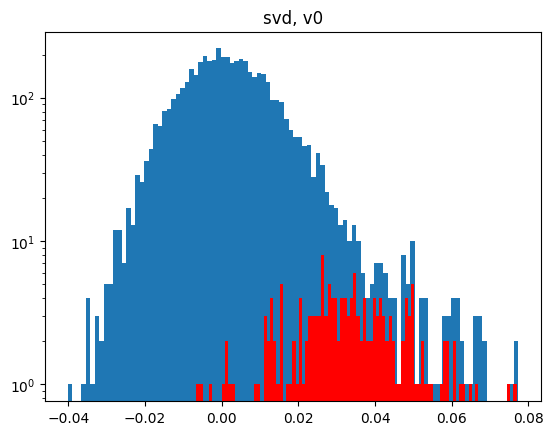

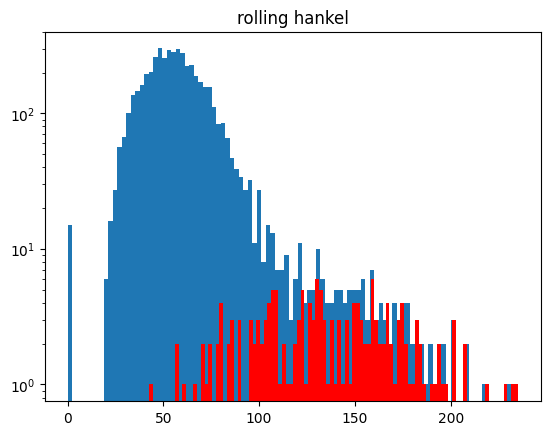

Text(0.5, 1.0, 'filtered')

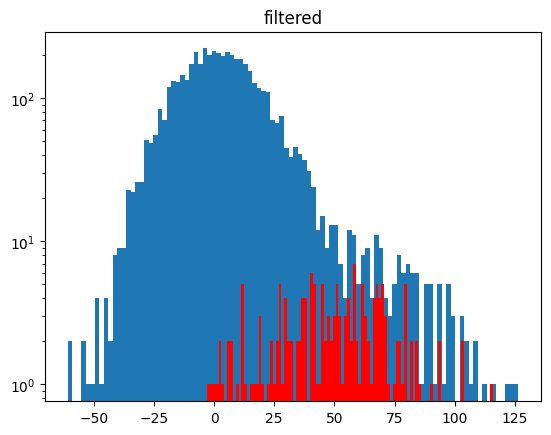

In [238]:
plt.hist(v[0][::-1], bins=100)
plt.hist(v[0][::-1][np.where(series > 15)], bins=100, color="r")
plt.semilogy()
plt.title("svd, v0")
plt.show()

plt.hist(singular_vals, bins=100)
plt.hist(singular_vals[np.where(series > 15)], bins=100, color="r")
plt.semilogy()
plt.title("rolling hankel")
plt.show()

plt.hist(filtered, bins=100)
plt.hist(filtered[np.where(series > 15)], bins=100, color="r")
plt.semilogy()
plt.title("filtered")